# Precious metals research results

Inspect one completed frozen experiment: data quality, validation model comparison, cost-aware portfolio results and holdout errors.

[Explorer guide (EN)](../docs/RESEARCH_EXPLORER.md) · [Руководство (RU)](../docs/RESEARCH_EXPLORER.ru.md)

This notebook reads saved results. Use `workflow.ipynb` or the research CLI to execute the pipeline. Set `CAPSTONE_RESEARCH_RUN` to choose a bundle; otherwise the most recently completed saved bundle is selected. Outputs below identify it explicitly.

## Context and methods

Signals use completed ETF sessions and evidenced COT availability. Models and thresholds were chosen on chronological validation; labels crossing split boundaries were purged. Charts of holdout errors are descriptive and must not guide further tuning on this same holdout.

### Key assumptions

Adjusted vendor prices may be revised. COT PRE metadata supports a conservative availability cutoff, rather than an original-release access log. Portfolio returns include configured costs and retain the full ETF universe. No historical result establishes future profitability.

In [1]:
from pathlib import Path
import os
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

project_root = next((p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
                     if (p / "pyproject.toml").is_file() and (p / "src/capstone").is_dir()), None)
if project_root is None:
    raise FileNotFoundError("Open this notebook within the standalone capstone checkout.")
os.chdir(project_root)
from capstone.reporting import (discover_runs, load_run, coverage_summary, feature_missingness,
                               training_rows, feature_correlations, equity_series, error_summary)
choices = discover_runs(project_root / "artifacts")
requested = os.environ.get("CAPSTONE_RESEARCH_RUN")
if not requested and not choices:
    raise FileNotFoundError("No completed bundle. Run capstone.research first or set CAPSTONE_RESEARCH_RUN.")
run = load_run(requested or choices[0])
plt.rcParams.update({"figure.figsize": (10, 4), "font.size": 11, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": .2})
display(Markdown(f"**Bundle:** `{run.path.name}`  \n**Selected model:** `{run.summary['selected_model']}`  \n"
                 f"**Holdout first signal:** {run.summary['split_dates']['test_start']}  \n"
                 f"**Model training-label cutoff:** {run.summary['model_training_last_exit']}"))

**Bundle:** `full-cot-current-code-20261121`  
**Selected model:** `mean`  
**Holdout first signal:** 2026-02-09  
**Model training-label cutoff:** 2026-02-06

## Data

Coverage and missingness describe the saved feature table. The target distribution and feature correlations below use **purged training rows only**.

,rows,labeled_rows,first_signal,last_signal
ticker,,,,
GLD,958,953,2022-10-31,2026-11-20
SLV,958,953,2022-10-31,2026-11-20


,fraction_missing
cot_managed_change,0.52%
cot_age_days,0.00%
nasdaq_return_5,0.00%
sp500_return_5,0.00%
nvda_return_5,0.00%
zec_return_5,0.00%
eth_return_5,0.00%
sol_return_5,0.00%
btc_return_5,0.00%
return_1,0.00%


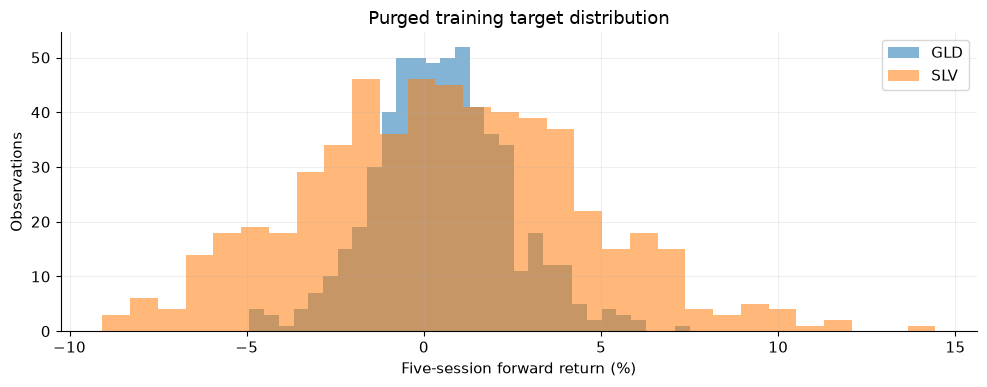

In [2]:
display(coverage_summary(run))
display(feature_missingness(run).to_frame().style.format("{:.2%}"))
train = training_rows(run)
fig, ax = plt.subplots()
for ticker, rows in train.groupby("ticker"):
    ax.hist(rows.target * 100, bins=30, alpha=.55, label=ticker)
ax.set(title="Purged training target distribution", xlabel="Five-session forward return (%)", ylabel="Observations")
ax.legend()
plt.tight_layout()
plt.show()

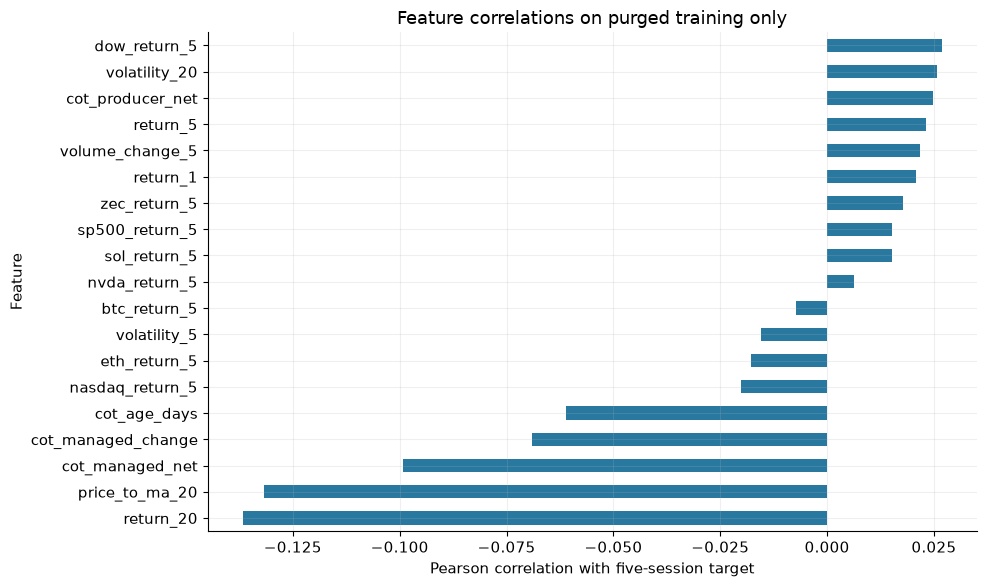

Correlations are descriptive. Overlapping labels and repeated COT values reduce independent information; these are not causal effects.

In [3]:
correlations = feature_correlations(run).dropna().sort_values()
fig, ax = plt.subplots(figsize=(10, 6))
correlations.plot.barh(ax=ax, color="#2878a0")
ax.set(title="Feature correlations on purged training only", xlabel="Pearson correlation with five-session target", ylabel="Feature")
plt.tight_layout()
plt.show()
display(Markdown("Correlations are descriptive. Overlapping labels and repeated COT values reduce independent information; these are not causal effects."))

## Results

### Validation selection

All candidate scores refer to validation. `selected=True` identifies the recorded minimum-MAE choice. Parameters are preserved as JSON; the table does not rank candidates using holdout.

In [4]:
display(run.tables["model_comparison"].style.format({"mae": "{:.4%}", "rmse": "{:.4%}"}))
display(run.tables["split_counts"])
display(Markdown("### Frozen holdout comparison"))
display(run.tables["holdout_comparison"].style.format({"mae": "{:.4%}", "rmse": "{:.4%}"}))

,model,split,mae,rmse,estimator,parameters,selected
0,mean,validation,3.6398%,5.8627%,DummyRegressor,"{""constant"": null, ""quantile"": null, ""strategy"": ""mean""}",True
1,tree_3,validation,3.6436%,5.8636%,DecisionTreeRegressor,"{""ccp_alpha"": 0.0, ""criterion"": ""squared_error"", ""max_depth"": 3, ""max_features"": null, ""max_leaf_nodes"": null, ""min_impurity_decrease"": 0.0, ""min_samples_leaf"": 20, ""min_samples_split"": 2, ""min_weight_fraction_leaf"": 0.0, ""monotonic_cst"": null, ""random_state"": 42, ""splitter"": ""best""}",False
2,forest_3,validation,3.6521%,5.8663%,RandomForestRegressor,"{""bootstrap"": true, ""ccp_alpha"": 0.0, ""criterion"": ""squared_error"", ""max_depth"": 3, ""max_features"": 1.0, ""max_leaf_nodes"": null, ""max_samples"": null, ""min_impurity_decrease"": 0.0, ""min_samples_leaf"": 10, ""min_samples_split"": 2, ""min_weight_fraction_leaf"": 0.0, ""monotonic_cst"": null, ""n_estimators"": 80, ""n_jobs"": 1, ""oob_score"": false, ""random_state"": 42, ""verbose"": 0, ""warm_start"": false}",False
3,forest_5,validation,3.6744%,5.8890%,RandomForestRegressor,"{""bootstrap"": true, ""ccp_alpha"": 0.0, ""criterion"": ""squared_error"", ""max_depth"": 5, ""max_features"": 1.0, ""max_leaf_nodes"": null, ""max_samples"": null, ""min_impurity_decrease"": 0.0, ""min_samples_leaf"": 10, ""min_samples_split"": 2, ""min_weight_fraction_leaf"": 0.0, ""monotonic_cst"": null, ""n_estimators"": 80, ""n_jobs"": 1, ""oob_score"": false, ""random_state"": 42, ""verbose"": 0, ""warm_start"": false}",False
4,tree_5,validation,3.6779%,5.8901%,DecisionTreeRegressor,"{""ccp_alpha"": 0.0, ""criterion"": ""squared_error"", ""max_depth"": 5, ""max_features"": null, ""max_leaf_nodes"": null, ""min_impurity_decrease"": 0.0, ""min_samples_leaf"": 20, ""min_samples_split"": 2, ""min_weight_fraction_leaf"": 0.0, ""monotonic_cst"": null, ""random_state"": 42, ""splitter"": ""best""}",False
5,ridge_10,validation,3.9805%,6.0961%,Ridge,"{""alpha"": 10.0, ""copy_X"": true, ""fit_intercept"": true, ""max_iter"": null, ""positive"": false, ""random_state"": null, ""solver"": ""auto"", ""tol"": 0.0001}",False
6,ridge_1,validation,4.0596%,6.1560%,Ridge,"{""alpha"": 1.0, ""copy_X"": true, ""fit_intercept"": true, ""max_iter"": null, ""positive"": false, ""random_state"": null, ""solver"": ""auto"", ""tol"": 0.0001}",False


,split,ticker,rows_before,rows_after,purged_rows,dates_after,first_signal,last_signal,last_exit
0,train,GLD,571,565,6,565,2022-10-31,2025-03-05,2025-03-13
1,train,SLV,571,565,6,565,2022-10-31,2025-03-05,2025-03-13
2,validation,GLD,191,185,6,185,2025-03-14,2026-01-29,2026-02-06
3,validation,SLV,191,185,6,185,2025-03-14,2026-01-29,2026-02-06
4,test,GLD,191,191,0,191,2026-02-09,2026-11-12,2026-11-20
5,test,SLV,191,191,0,191,2026-02-09,2026-11-12,2026-11-20


### Frozen holdout comparison

,model,mae,rmse
0,mean,4.4257%,5.8827%
1,mean,4.4257%,5.8827%


### Portfolio and benchmark

Cumulative return uses the original initial capital. Drawdown includes entry costs and is measured against the running equity peak, bounded below by initial capital. All target ETFs remain included.

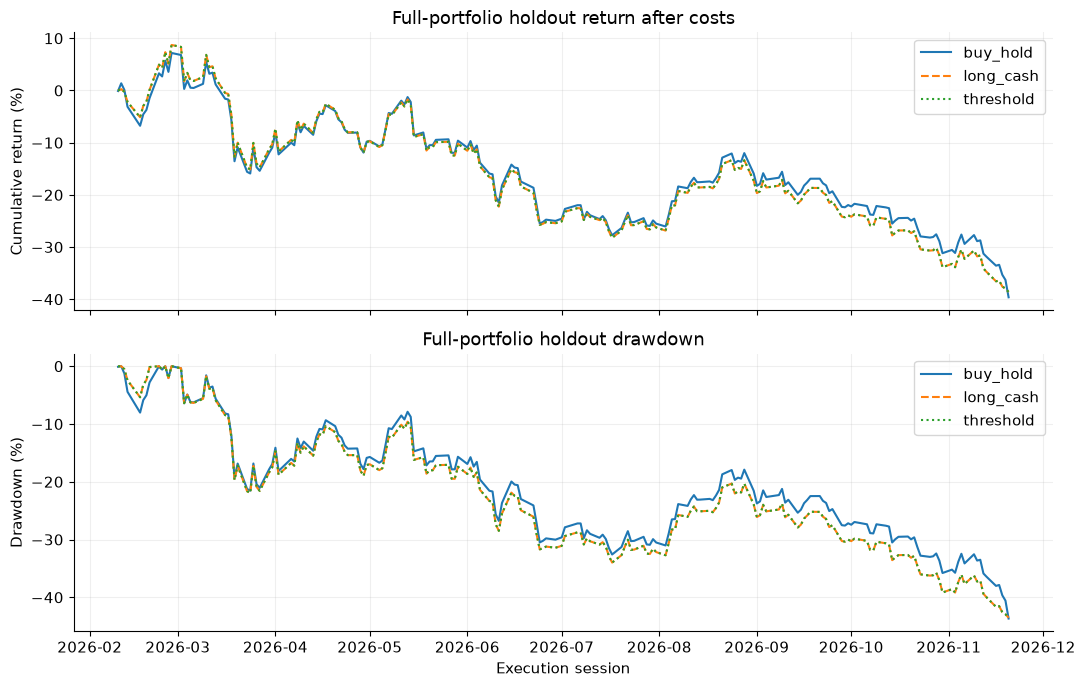

,strategy,total_return,cagr,sharpe,max_drawdown,gross_traded_notional,transaction_costs,executions,round_trips
0,long_cash,-38.61%,-46.72%,-1.556,-43.53%,6398529.272833,"6,398.53",764,382
1,threshold,-38.61%,-46.72%,-1.556,-43.53%,6398529.272833,"6,398.53",764,382
2,buy_hold,-39.63%,-47.86%,-1.565,-43.67%,160334.560963,160.33,4,2


In [5]:
curve = equity_series(run)
fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
styles = ["-", "--", ":"]
for i, (strategy, rows) in enumerate(curve.groupby("strategy")):
    axes[0].plot(rows.date, rows.net_return * 100, label=strategy, linestyle=styles[i % len(styles)])
    axes[1].plot(rows.date, rows.drawdown * 100, label=strategy, linestyle=styles[i % len(styles)])
axes[0].set(title="Full-portfolio holdout return after costs", ylabel="Cumulative return (%)")
axes[1].set(title="Full-portfolio holdout drawdown", ylabel="Drawdown (%)", xlabel="Execution session")
for ax in axes:
    ax.legend()
plt.tight_layout()
plt.show()
display(run.tables["metrics"].style.format({"total_return": "{:.2%}", "cagr": "{:.2%}", "max_drawdown": "{:.2%}",
                                          "sharpe": "{:.3f}", "transaction_costs": "{:,.2f}"}))

### Holdout errors and wrong predictions

These are post-selection diagnostics by ticker. The largest errors are examples from this particular holdout, not a new selection sample.

,ticker,count,mae,bias,rmse
0,GLD,191,3.030%,1.544%,3.917%
1,SLV,191,5.821%,2.066%,7.339%


,date,ticker,target,prediction,absolute_error
43,2026-03-11 00:00:00,SLV,-21.177%,0.868%,22.044%
177,2026-06-16 00:00:00,SLV,-17.044%,0.868%,17.912%
175,2026-06-15 00:00:00,SLV,-16.892%,0.868%,17.759%
47,2026-03-13 00:00:00,SLV,-16.325%,0.868%,17.193%
11,2026-02-17 00:00:00,SLV,17.514%,0.868%,16.646%
49,2026-03-16 00:00:00,SLV,-15.774%,0.868%,16.641%
381,2026-11-12 00:00:00,SLV,-15.208%,0.868%,16.075%
45,2026-03-12 00:00:00,SLV,-14.973%,0.868%,15.841%
159,2026-06-03 00:00:00,SLV,-14.889%,0.868%,15.757%
9,2026-02-13 00:00:00,SLV,16.293%,0.868%,15.425%


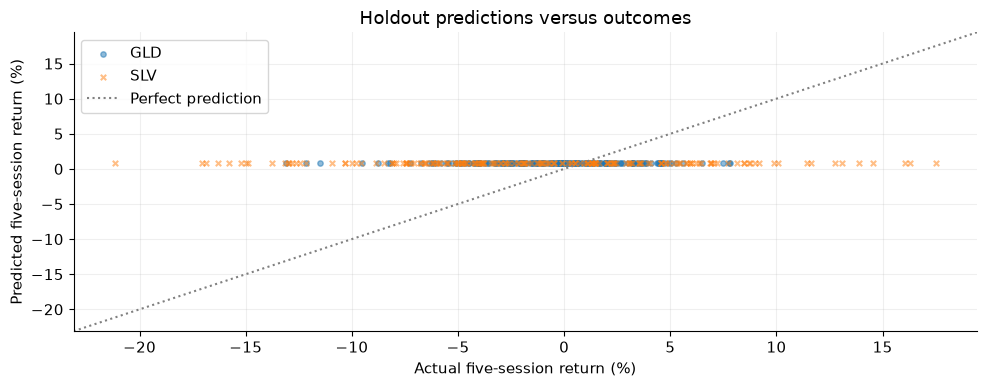

In [6]:
display(error_summary(run).style.format({"mae": "{:.3%}", "rmse": "{:.3%}", "bias": "{:.3%}"}))
errors = run.tables["test_errors"].copy()
errors["absolute_error"] = (errors.prediction - errors.target).abs()
display(errors.nlargest(10, "absolute_error")[["date", "ticker", "target", "prediction", "absolute_error"]]
        .style.format({"target": "{:.3%}", "prediction": "{:.3%}", "absolute_error": "{:.3%}"}))
fig, ax = plt.subplots()
for i, (ticker, rows) in enumerate(errors.groupby("ticker")):
    ax.scatter(rows.target * 100, rows.prediction * 100, label=ticker, alpha=.5, s=15, marker=["o", "x"][i % 2])
lower = min(errors.target.min(), errors.prediction.min()) * 100
upper = max(errors.target.max(), errors.prediction.max()) * 100
padding = max((upper - lower) * .05, .1)
bounds = [lower - padding, upper + padding]
ax.plot(bounds, bounds, linestyle=":", color="gray", label="Perfect prediction")
ax.set(title="Holdout predictions versus outcomes", xlabel="Actual five-session return (%)", ylabel="Predicted five-session return (%)", xlim=bounds, ylim=bounds)
ax.legend()
plt.tight_layout()
plt.show()

## Takeaways

The following summary is calculated from the selected saved run. Changes to features or strategies motivated by these errors need a new evaluation design; this holdout has already been inspected.

In [7]:
selected = run.tables["model_comparison"].loc[lambda t: t.selected].iloc[0]
metrics = run.tables["metrics"].set_index("strategy")
lines = [f"- Validation selected **{selected['model']}**, MAE **{selected.mae:.4%}**, RMSE **{selected.rmse:.4%}**."]
for strategy, values in metrics.iterrows():
    lines.append(f"- `{strategy}`: holdout return **{values.total_return:.2%}**, maximum drawdown **{values.max_drawdown:.2%}**, paid costs **{values.transaction_costs:,.2f}**.")
if {"long_cash", "threshold"}.issubset(metrics.index) and metrics.loc["long_cash"].equals(metrics.loc["threshold"]):
    lines.append("- Long/cash and threshold have identical recorded metrics in this run; they are not independent empirical strategies.")
lines.append("- Source vintage, COT timestamp assumptions, the fixed two-ETF universe and the single inspected holdout limit conclusions.")
display(Markdown("\n".join(lines)))

- Validation selected **mean**, MAE **3.6398%**, RMSE **5.8627%**.
- `long_cash`: holdout return **-38.61%**, maximum drawdown **-43.53%**, paid costs **6,398.53**.
- `threshold`: holdout return **-38.61%**, maximum drawdown **-43.53%**, paid costs **6,398.53**.
- `buy_hold`: holdout return **-39.63%**, maximum drawdown **-43.67%**, paid costs **160.33**.
- Long/cash and threshold have identical recorded metrics in this run; they are not independent empirical strategies.
- Source vintage, COT timestamp assumptions, the fixed two-ETF universe and the single inspected holdout limit conclusions.